In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFECV
from sklearn.datasets import make_classification

# Build a classification task using 3 informative features
X, y = make_classification(
    n_samples=1000,
    n_features=25,
    n_informative=3,
    n_redundant=2,
    n_repeated=0,
    n_classes=8,
    n_clusters_per_class=1,
    random_state=0,
)

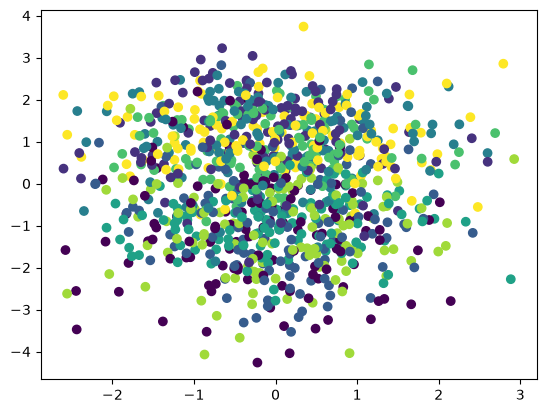

In [4]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

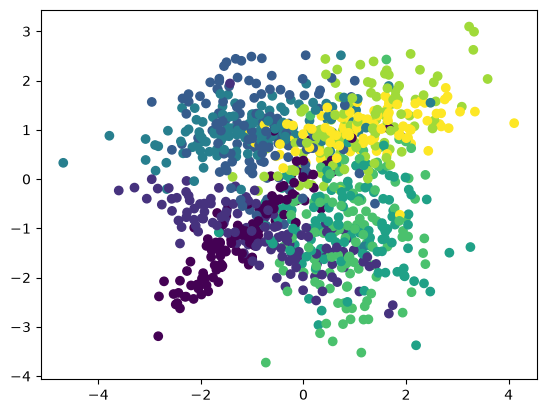

In [3]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(X[:, 7], X[:, 18], c=y)
plt.show()

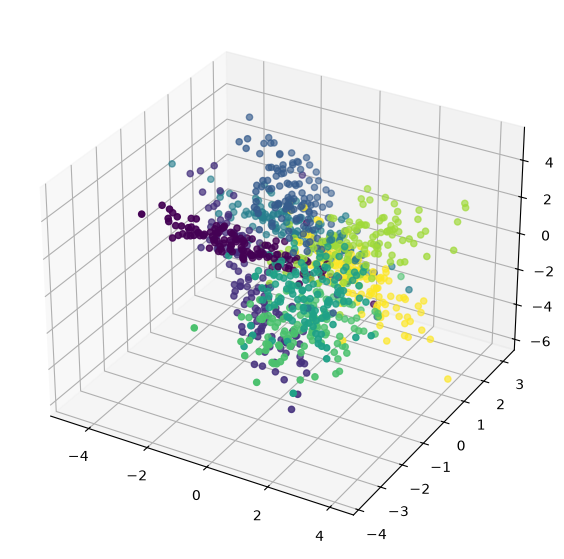

In [4]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(X[:, 7], X[:, 18], X[:, 8], c=y)
 
# show plot
plt.show()

### Pair Plot vs Correlação

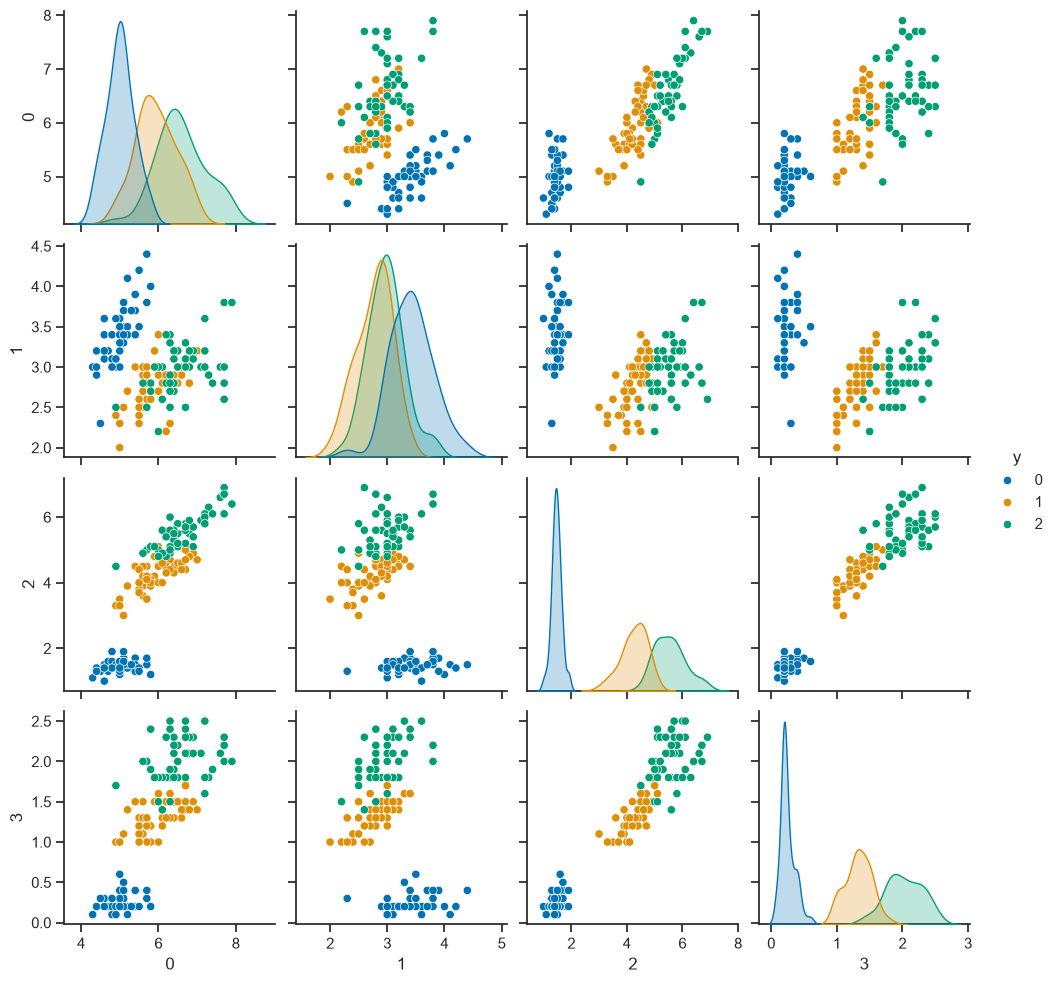

In [13]:
import pandas as pd
import seaborn as sns

#data = pd.DataFrame(X)
#data['y'] = y

from sklearn.datasets import load_iris
data_iris = load_iris()
X = data_iris.data
y = data_iris.target

data = pd.DataFrame(data_iris.data)
data['y'] = data_iris.target

sns.set(style="ticks")
sns.pairplot(data, hue='y', palette="colorblind")

<Axes: >

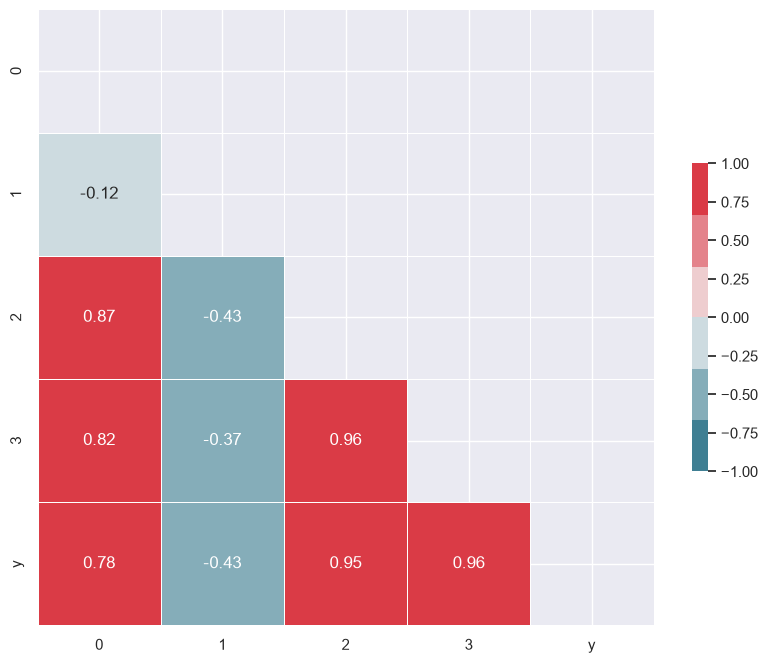

In [17]:
#method{‘pearson’, ‘kendall’, ‘spearman’}
corr = data.corr(method="pearson")

sns.set(style="darkgrid")

f, ax = plt.subplots(figsize=(10, 8))

mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)]=True

cmap = sns.diverging_palette(220, 10)

sns.heatmap(corr, mask=mask, annot=True, cmap=cmap,
            vmax=1, vmin=-1, center=0, square=True, 
            linewidth=.5,cbar_kws={"shrink":.5})

# Cross Correlation

In [14]:
from scipy import signal
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng()

In [15]:
sig = np.repeat([0., 1., 1., 0., 1., 0., 0., 1.], 128)
sig_noise = sig + rng.standard_normal(len(sig))
corr = signal.correlate(sig_noise, np.ones(128), mode='same') / 128

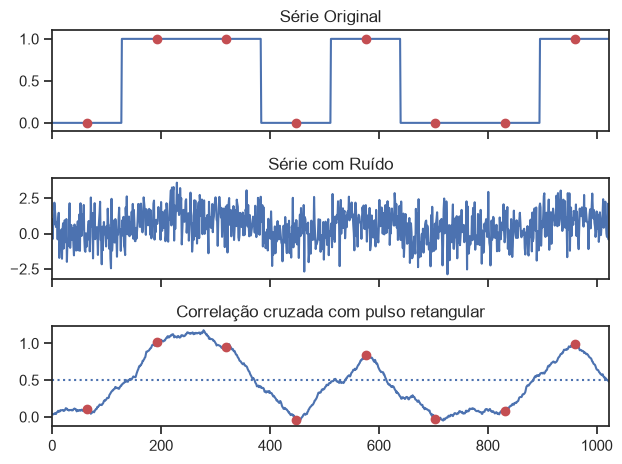

In [16]:
clock = np.arange(64, len(sig), 128)
fig, (ax_orig, ax_noise, ax_corr) = plt.subplots(3, 1, sharex=True)

ax_orig.plot(sig)
ax_orig.plot(clock, sig[clock], 'ro')
ax_orig.set_title('Série Original')

ax_noise.plot(sig_noise)
ax_noise.set_title('Série com Ruído')

ax_corr.plot(corr)
ax_corr.plot(clock, corr[clock], 'ro')
ax_corr.axhline(0.5, ls=':')
ax_corr.set_title('Correlação cruzada com pulso retangular')

ax_orig.margins(0, 0.1)

fig.tight_layout()
plt.show()

In [17]:
x = np.arange(128) / 128 #  amostra
sig = np.sin(2 * np.pi * x) # série
sig_noise = sig + rng.standard_normal(len(sig))/2 # série com ruído

corr = signal.correlate(sig_noise, sig)
lags = signal.correlation_lags(len(sig), len(sig_noise))
corr /= np.max(corr)

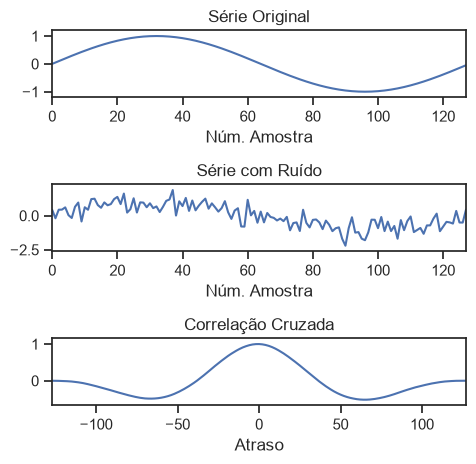

In [18]:
fig, (ax_orig, ax_noise, ax_corr) = plt.subplots(3, 1, figsize=(4.8, 4.8))

ax_orig.plot(sig)
ax_orig.set_title('Série Original')
ax_orig.set_xlabel('Núm. Amostra')

ax_noise.plot(sig_noise)
ax_noise.set_title('Série com Ruído')
ax_noise.set_xlabel('Núm. Amostra')

ax_corr.plot(lags, corr)
ax_corr.set_title('Correlação Cruzada')
ax_corr.set_xlabel('Atraso')

ax_orig.margins(0, 0.1)
ax_noise.margins(0, 0.1)
ax_corr.margins(0, 0.1)

fig.tight_layout()
plt.show()

# SHAP

In [24]:
#!pip install shap
import sklearn
from sklearn.linear_model import LogisticRegression
import shap

# a classic housing price dataset
#X, y = shap.datasets.california(n_points=1000)

X100 = shap.utils.sample(X, 100)  # 100 instances for use as the background distribution

# a simple linear model
model = LogisticRegression(max_iter=10000)
model.fit(X, y)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [25]:
# compute the SHAP values for the linear model
explainer = shap.Explainer(model.predict, X100)
shap_values = explainer(X)

# make a standard partial dependence plot
sample_ind = 20
"""
shap.partial_dependence_plot(
    "MedInc",
    model.predict,
    X100,
    model_expected_value=True,
    feature_expected_value=True,
    ice=False,
    shap_values=shap_values[sample_ind : sample_ind + 1, :],
)
"""

PermutationExplainer explainer: 1001it [00:23, 22.42it/s]                         


'\nshap.partial_dependence_plot(\n    "MedInc",\n    model.predict,\n    X100,\n    model_expected_value=True,\n    feature_expected_value=True,\n    ice=False,\n    shap_values=shap_values[sample_ind : sample_ind + 1, :],\n)\n'

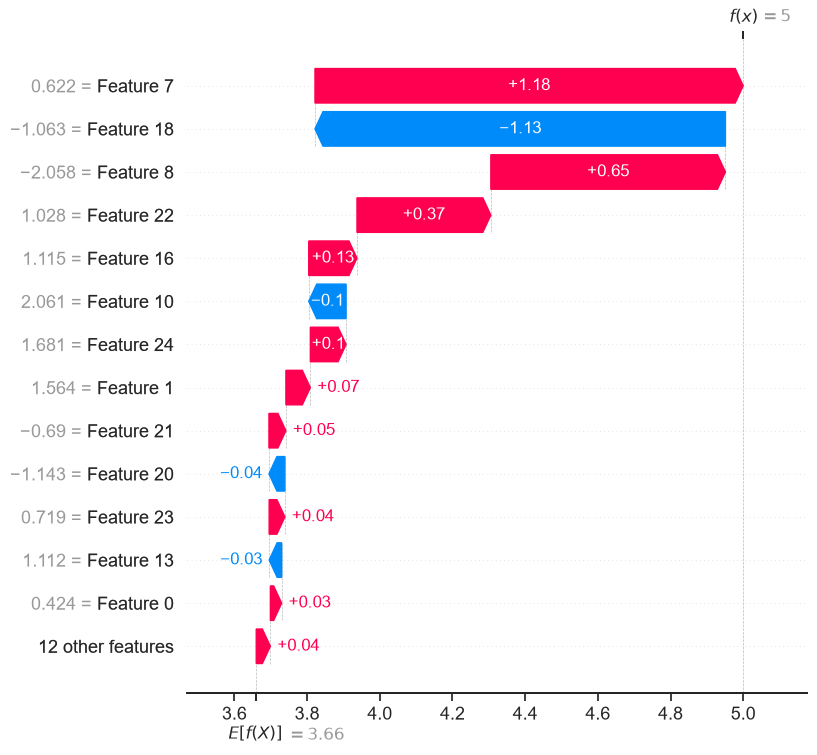

In [26]:
# the waterfall_plot shows how we get from shap_values.base_values to model.predict(X)[sample_ind]
shap.plots.waterfall(shap_values[sample_ind], max_display=14)

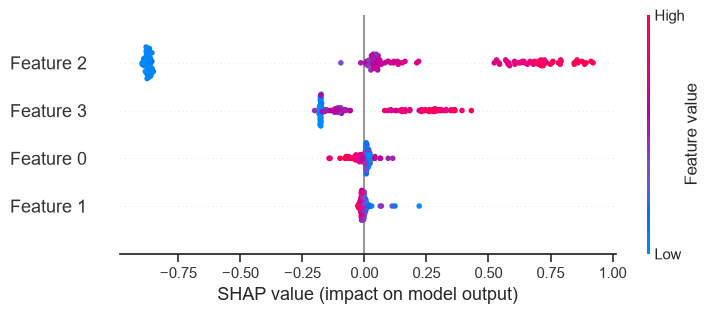

In [22]:
shap.plots.beeswarm(
    shap_values, max_display=14
)

# RFE - Recursive Feature Elimination

In [5]:
from sklearn.feature_selection import RFECV
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression


from sklearn.datasets import load_iris
#data_iris = load_iris()
#X = data_iris.data
#y = data_iris.target

#from sklearn.datasets import load_digits
#digits = load_digits()
#X = digits.data
#y = digits.target

#svc = SVC(kernel="linear", max_iter=10000)
logreg = LogisticRegression(max_iter=10000)

rfe = RFE(logreg, n_features_to_select=3, step=1)
rfe.fit(X, y)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",LogisticRegre...ax_iter=10000)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",3
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](8,)","[0,1,2,...,5,6,7]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,LogisticRegression,LogisticRegre...ax_iter=10000)
n_features_ n_features_: intThe number of selected features.,int64,np.int64(3)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,25
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](25,)","[ 6, 1,22,..., 3, 7,21]"


In [6]:
rfe.support_

array([False,  True, False, False, False, False, False,  True, False,
       False, False, False, False, False, False, False, False, False,
        True, False, False, False, False, False, False])

In [7]:
rfe.ranking_

array([ 6,  1, 22, 17,  8,  9, 10,  1,  2, 16, 19, 11, 12, 14, 15,  4,  5,
       23,  1, 13, 20, 18,  3,  7, 21])

In [9]:
sel_X = X[:,rfe.support_]

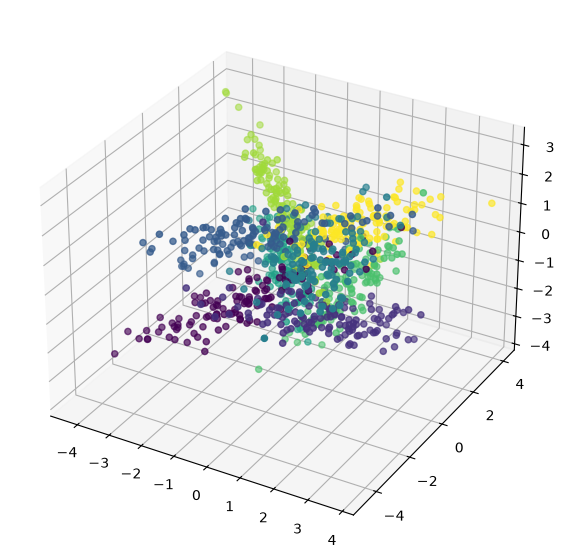

In [10]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = fig.add_subplot(111, projection="3d")
 
# Creating plot
ax.scatter3D(sel_X[:, 0], sel_X[:, 1], sel_X[:, 2], c=y)#, cmap='viridis')

#ax.scatter3D(X[:, 0], X[:, 1], X[:, 2], c=y, cmap='viridis')
#ax.scatter3D(X[:, 0], X[:, 6], X[:, 11], c=y)


#sel_X = X[:,rfe.support_]
#ax.scatter3D(sel_X[:, 0], sel_X[:, 1], sel_X[:, 2], c=y)
#ax.scatter3D(X[:, 0], X[:, 6], X[:, 11], c=y)
# show plot
plt.show()

In [44]:
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
#svc = SVC(kernel="linear", max_iter=10000)

logreg = LogisticRegression(max_iter=10000)

#rfe = RFE(estimator, n_features_to_select=5, step=1)
#rfe.fit(X, y)

min_features_to_select = 1  # Minimum number of features to consider
rfecv = RFECV(
    estimator=logreg,
    step=1,
    cv=StratifiedKFold(10),
    scoring="accuracy",
    min_features_to_select=min_features_to_select
)
#rfecv.fit(X, y)
rfecv.fit(data.data, data.target)
print("Número ótimo de atributos : %d" % rfecv.n_features_)

Número ótimo de atributos : 13


In [34]:
# 1, 7, 8, 15, 16, 18, 22
rfecv.support_

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True])

In [35]:
rfecv.ranking_

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

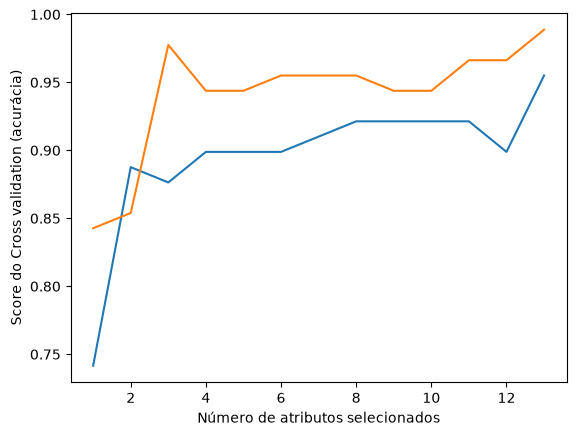

In [36]:
# Plot number of features VS. cross-validation scores
plt.figure()
plt.xlabel("Número de atributos selecionados")
plt.ylabel("Score do Cross validation (acurácia)")

grid_scores_  = np.column_stack((rfecv.cv_results_['split0_test_score'], rfecv.cv_results_['split1_test_score']))
plt.plot(
    range(min_features_to_select, len(grid_scores_) + min_features_to_select),
    grid_scores_,
)
plt.show()

In [35]:
rfecv.support_

array([False, False,  True,  True])

In [36]:
rfecv.ranking_

array([3, 2, 1, 1])

In [37]:
sel_X = X[:,rfecv.support_]

In [15]:
import numpy as np
import copy as cp
from typing import Tuple
from sklearn.model_selection import StratifiedKFold, cross_val_score

def cross_val_predict(model, kfold : StratifiedKFold, X : np.array, y : np.array) -> Tuple[np.array, np.array, np.array]:

    model_ = cp.deepcopy(model)

    no_classes = len(np.unique(y))

    actual_classes = np.empty([0], dtype=int)
    predicted_classes = np.empty([0], dtype=int)
    predicted_proba = np.empty([0, no_classes])

    for train_ndx, test_ndx in kfold.split(X,y):

        train_X, train_y, test_X, test_y = X[train_ndx], y[train_ndx], X[test_ndx], y[test_ndx]

        actual_classes = np.append(actual_classes, test_y)

        model_.fit(train_X, train_y)
        predicted_classes = np.append(predicted_classes, model_.predict(test_X))

        try:
            predicted_proba = np.append(predicted_proba, model_.predict_proba(test_X), axis=0)
        except:
            predicted_proba = np.append(predicted_proba, np.zeros((len(test_X), no_classes), dtype=float), axis=0)

    return actual_classes, predicted_classes, predicted_proba

In [39]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

X = sel_X

lr = LogisticRegression(max_iter=1000)

# Validação cruzada estratificada K Fold (ou K-Fold estratificado)
kfold = StratifiedKFold(n_splits=10,  shuffle=False)

cv_results = cross_val_score(lr, X,y, scoring='accuracy', cv=kfold)
actual_classes, predicted_classes, _ = cross_val_predict(lr, kfold, X,y)
print(cv_results.mean())

0.96


In [40]:
from sklearn.model_selection import train_test_split

sel_X = data_iris.data
y = data_iris.target

X_train, X_test, Y_train, Y_test = train_test_split(sel_X,y, test_size=0.25)

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train, Y_train)

print(lr.score(X_test, Y_test))

0.9736842105263158


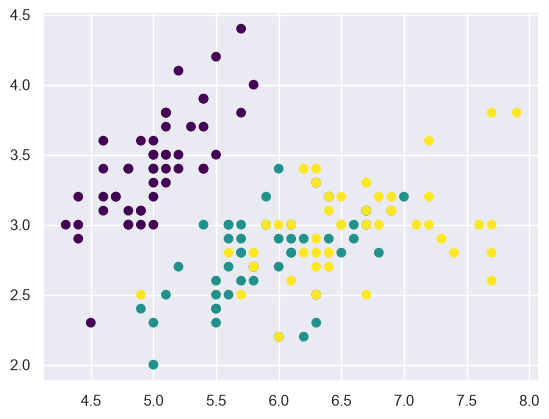

In [41]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(sel_X[:, 0], sel_X[:, 1], c=y)
plt.show()

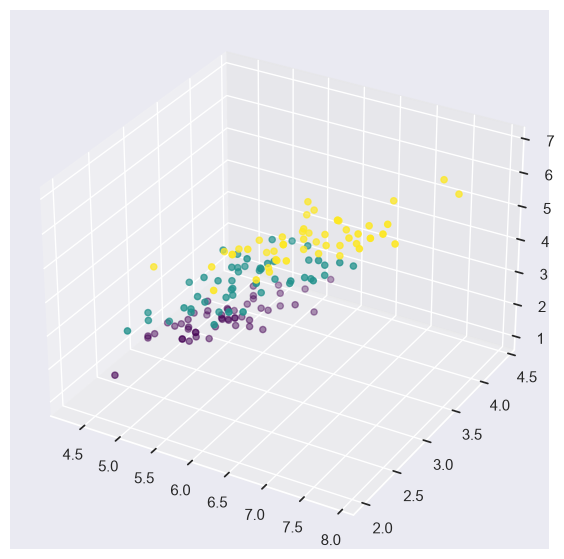

In [42]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(sel_X[:, 0], sel_X[:, 1], sel_X[:, 2], c=y)
#ax.scatter3D(X[:, 0], X[:, 1], X[:, 2], c=y)
 
# show plot
plt.show()

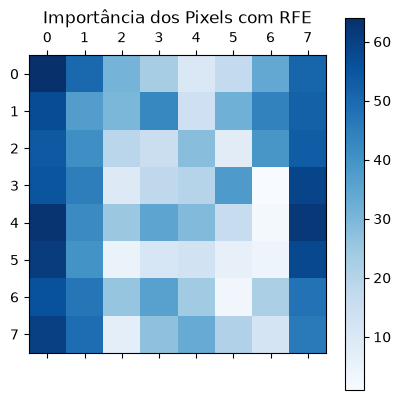

In [16]:
from sklearn.svm import SVC
from sklearn.datasets import load_digits
from sklearn.feature_selection import RFE
import matplotlib.pyplot as plt

# Load the digits dataset
digits = load_digits()
dX = digits.images.reshape((len(digits.images), -1))
dy = digits.target

# Create the RFE object and rank each pixel
svc = SVC(kernel="linear", C=1)
rfe = RFE(estimator=svc, n_features_to_select=1, step=1)
rfe.fit(dX, dy)
ranking = rfe.ranking_.reshape(digits.images[0].shape)

# Plot pixel ranking
plt.matshow(ranking, cmap=plt.cm.Blues)
plt.colorbar()
plt.title("Importância dos Pixels com RFE")
plt.show()

# MRMR

In [44]:
data

,0,1,2,3,y
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [31]:
from sklearn.datasets import load_wine
#https://github.com/danielhomola/mifs
#np.bool foi deprecaded - corrigido em 20/set/2026 
#sklearn.feature_selection._base corrigido em 20/set/2026 
from mifs import mifs

# define MI_FS feature selection method
#'JMI' : Joint Mutual Information [1]
#'JMIM' : Joint Mutual Information Maximisation [2]
#'MRMR' : Max-Relevance Min-Redundancy [3]
feat_selector = mifs.MutualInformationFeatureSelector(method='MRMR',n_features=3)

# find all relevant features
data = load_wine()
#feat_selector.fit(X, y)
feat_selector.fit(data.data, data.target)

# check selected features
print(feat_selector._support_mask)

# check ranking of features
print(feat_selector.ranking_)

# call transform() on X to filter it down to selected features
#X_filtered = feat_selector.transform(X)
X_filtered = feat_selector.transform(data.data)

[False False False False False False  True False False  True False False
 False]
[6, 9]


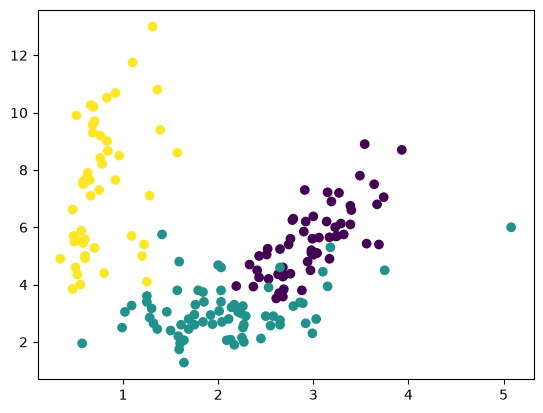

In [32]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(data.data[:, 6], data.data[:, 9], c=data.target)
#plt.scatter(X[:, 18], X[:, 8], c=y)
plt.show()

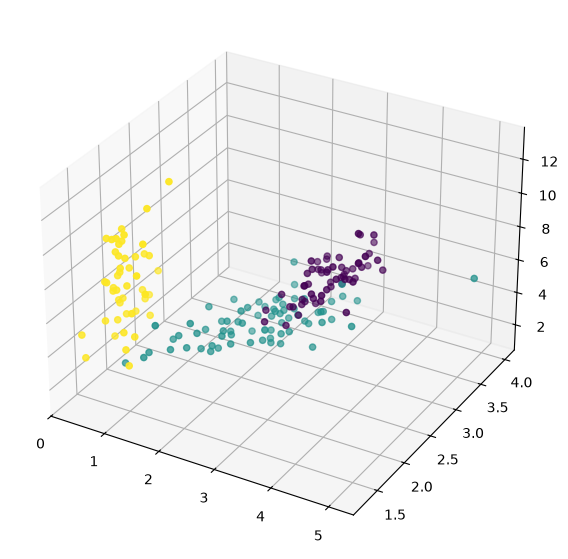

In [40]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
#ax.scatter3D(X[:, 18], X[:, 8], X[:, 1], c=y)
ax.scatter3D(data.data[:, 6], data.data[:, 11], data.data[:, 9], c=data.target)
 
# show plot
plt.show()

In [37]:
#sel_X = X[:,feat_selector._support_mask]
sel_X = data.data[:,feat_selector._support_mask]

from sklearn.model_selection import train_test_split

#X_train, X_test, Y_train, Y_test = train_test_split(sel_X,y, test_size=0.25)
X_train, X_test, Y_train, Y_test = train_test_split(sel_X,data.target, test_size=0.25)

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train, Y_train)

print(lr.score(X_test, Y_test))

0.9111111111111111


In [49]:
feat_selector.ranking_

[6, 9]

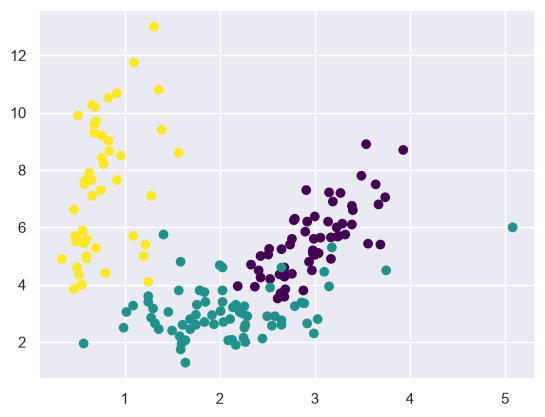

In [50]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(data.data[:, feat_selector.ranking_[0]],data.data[:, feat_selector.ranking_[1]], c=data.target)
plt.show()

In [51]:
Y_pred = lr.predict(X_test)

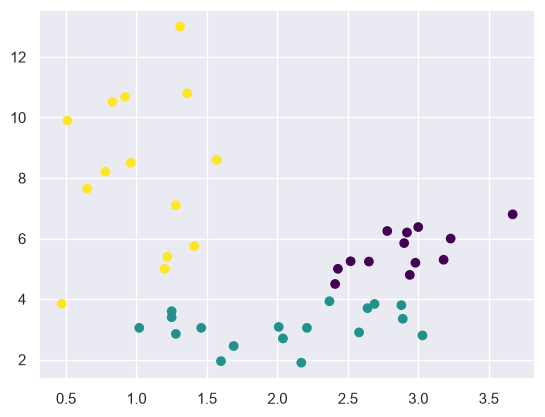

In [52]:
import matplotlib.pyplot as plt

plt.viridis()
plt.scatter(X_test[:,0], X_test[:,1], c=Y_pred)
plt.show()

In [53]:
'''
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(X[:, feat_selector.ranking_[0]],X[:, feat_selector.ranking_[1]],X[:, feat_selector.ranking_[2]], c=y)
 
# show plot
plt.show()
'''

'\nimport matplotlib.pyplot as plt\n\n# Creating figure\nfig = plt.figure(figsize = (10, 7))\nax = plt.axes(projection ="3d")\n\n# Creating plot\nax.scatter3D(X[:, feat_selector.ranking_[0]],X[:, feat_selector.ranking_[1]],X[:, feat_selector.ranking_[2]], c=y)\n\n# show plot\nplt.show()\n'

In [54]:
len(X_filtered[0])

2

In [55]:
#pip install mrmr_selection
import pandas as pd
from mrmr import mrmr_classif

selected_features = mrmr_classif(pd.DataFrame(X), pd.Series(y), K = 3)
print(selected_features)

100%|██████████| 2/2 [00:00<00:00, 209.10it/s]

[0, 1]


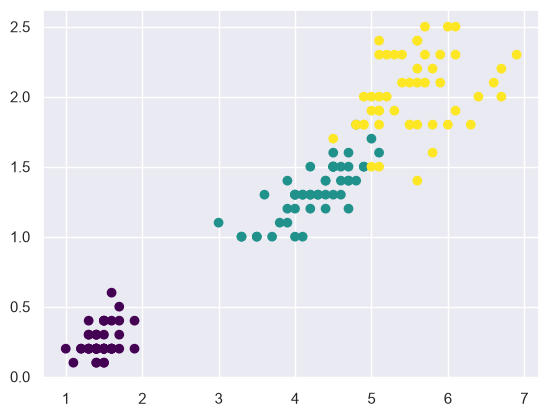

In [57]:
import matplotlib.pyplot as plt
plt.viridis()
#plt.scatter(X[:, 6],X[:, 3], c=y)
plt.scatter(X[:, 0],X[:, 1], c=y)
plt.show()

IndexError: index 2 is out of bounds for axis 1 with size 2

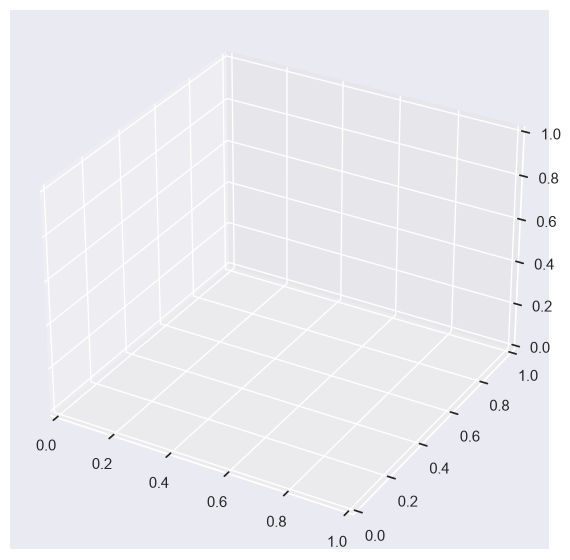

In [59]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
#ax.scatter3D(X[:, 6], X[:, 9], X[:, 12], c=y)
ax.scatter3D(X[:, 0], X[:, 1], X[:, 2], c=y)
 
# show plot
plt.show()

# CBFS - Correlation-Based Feature Selection

In [23]:
import scipy.spatial as ss
from scipy.special import digamma
from math import log
import numpy.random as nr
import numpy as np
import random


# continuous estimators

def entropy(x, k=3, base=2):
    """
    The classic K-L k-nearest neighbor continuous entropy estimator x should be a list of vectors,
    e.g. x = [[1.3],[3.7],[5.1],[2.4]] if x is a one-dimensional scalar and we have four samples
    """

    assert k <= len(x)-1, "Set k smaller than num. samples - 1"
    d = len(x[0])
    N = len(x)
    intens = 1e-10  # small noise to break degeneracy, see doc.
    x = [list(p + intens * nr.rand(len(x[0]))) for p in x]
    tree = ss.cKDTree(x)
    nn = [tree.query(point, k+1, p=float('inf'))[0][k] for point in x]
    const = digamma(N)-digamma(k) + d*log(2)
    return (const + d*np.mean(map(log, nn)))/log(base)


def mi(x, y, k=3, base=2):
    """
    Mutual information of x and y; x, y should be a list of vectors, e.g. x = [[1.3],[3.7],[5.1],[2.4]]
    if x is a one-dimensional scalar and we have four samples
    """

    assert len(x) == len(y), "Lists should have same length"
    assert k <= len(x) - 1, "Set k smaller than num. samples - 1"
    intens = 1e-10  # small noise to break degeneracy, see doc.
    x = [list(p + intens * nr.rand(len(x[0]))) for p in x]
    y = [list(p + intens * nr.rand(len(y[0]))) for p in y]
    points = zip2(x, y)
    # Find nearest neighbors in joint space, p=inf means max-norm
    tree = ss.cKDTree(points)
    dvec = [tree.query(point, k+1, p=float('inf'))[0][k] for point in points]
    a, b, c, d = avgdigamma(x, dvec), avgdigamma(y, dvec), digamma(k), digamma(len(x))
    return (-a-b+c+d)/log(base)


def cmi(x, y, z, k=3, base=2):
    """
    Mutual information of x and y, conditioned on z; x, y, z should be a list of vectors, e.g. x = [[1.3],[3.7],[5.1],[2.4]]
    if x is a one-dimensional scalar and we have four samples
    """

    assert len(x) == len(y), "Lists should have same length"
    assert k <= len(x) - 1, "Set k smaller than num. samples - 1"
    intens = 1e-10  # small noise to break degeneracy, see doc.
    x = [list(p + intens * nr.rand(len(x[0]))) for p in x]
    y = [list(p + intens * nr.rand(len(y[0]))) for p in y]
    z = [list(p + intens * nr.rand(len(z[0]))) for p in z]
    points = zip2(x, y, z)
    # Find nearest neighbors in joint space, p=inf means max-norm
    tree = ss.cKDTree(points)
    dvec = [tree.query(point, k+1, p=float('inf'))[0][k] for point in points]
    a, b, c, d = avgdigamma(zip2(x, z), dvec), avgdigamma(zip2(y, z), dvec), avgdigamma(z, dvec), digamma(k)
    return (-a-b+c+d)/log(base)


def kldiv(x, xp, k=3, base=2):
    """
    KL Divergence between p and q for x~p(x), xp~q(x); x, xp should be a list of vectors, e.g. x = [[1.3],[3.7],[5.1],[2.4]]
    if x is a one-dimensional scalar and we have four samples
    """

    assert k <= len(x) - 1, "Set k smaller than num. samples - 1"
    assert k <= len(xp) - 1, "Set k smaller than num. samples - 1"
    assert len(x[0]) == len(xp[0]), "Two distributions must have same dim."
    d = len(x[0])
    n = len(x)
    m = len(xp)
    const = log(m) - log(n-1)
    tree = ss.cKDTree(x)
    treep = ss.cKDTree(xp)
    nn = [tree.query(point, k+1, p=float('inf'))[0][k] for point in x]
    nnp = [treep.query(point, k, p=float('inf'))[0][k-1] for point in x]
    return (const + d*np.mean(map(log, nnp))-d*np.mean(map(log, nn)))/log(base)


# Discrete estimators
def entropyd(sx, base=2):
    """
    Discrete entropy estimator given a list of samples which can be any hashable object
    """

    return entropyfromprobs(hist(sx), base=base)


def midd(x, y):
    """
    Discrete mutual information estimator given a list of samples which can be any hashable object
    """

    return -entropyd(list(zip(x, y)))+entropyd(x)+entropyd(y)


def cmidd(x, y, z):
    """
    Discrete mutual information estimator given a list of samples which can be any hashable object
    """

    return entropyd(list(zip(y, z)))+entropyd(list(zip(x, z)))-entropyd(list(zip(x, y, z)))-entropyd(z)


def hist(sx):
    # Histogram from list of samples
    d = dict()
    for s in sx:
        d[s] = d.get(s, 0) + 1
    return map(lambda z: float(z)/len(sx), d.values())


def entropyfromprobs(probs, base=2):
    # Turn a normalized list of probabilities of discrete outcomes into entropy (base 2)
    return -sum(map(elog, probs))/log(base)


def elog(x):
    # for entropy, 0 log 0 = 0. but we get an error for putting log 0
    if x <= 0. or x >= 1.:
        return 0
    else:
        return x*log(x)


# Mixed estimators
def micd(x, y, k=3, base=2, warning=True):
    """ If x is continuous and y is discrete, compute mutual information
    """

    overallentropy = entropy(x, k, base)
    n = len(y)
    word_dict = dict()
    for sample in y:
        word_dict[sample] = word_dict.get(sample, 0) + 1./n
    yvals = list(set(word_dict.keys()))

    mi = overallentropy
    for yval in yvals:
        xgiveny = [x[i] for i in range(n) if y[i] == yval]
        if k <= len(xgiveny) - 1:
            mi -= word_dict[yval]*entropy(xgiveny, k, base)
        else:
            if warning:
                print("Warning, after conditioning, on y={0} insufficient data. Assuming maximal entropy in this case.".format(yval))
            mi -= word_dict[yval]*overallentropy
    return mi  # units already applied


# Utility functions
def vectorize(scalarlist):
    """
    Turn a list of scalars into a list of one-d vectors
    """

    return [(x,) for x in scalarlist]


def shuffle_test(measure, x, y, z=False, ns=200, ci=0.95, **kwargs):
    """
    Shuffle test
    Repeatedly shuffle the x-values and then estimate measure(x,y,[z]).
    Returns the mean and conf. interval ('ci=0.95' default) over 'ns' runs, 'measure' could me mi,cmi,
    e.g. Keyword arguments can be passed. Mutual information and CMI should have a mean near zero.
    """

    xp = x[:]   # A copy that we can shuffle
    outputs = []
    for i in range(ns):
        random.shuffle(xp)
        if z:
            outputs.append(measure(xp, y, z, **kwargs))
        else:
            outputs.append(measure(xp, y, **kwargs))
    outputs.sort()
    return np.mean(outputs), (outputs[int((1.-ci)/2*ns)], outputs[int((1.+ci)/2*ns)])


# Internal functions
def avgdigamma(points, dvec):
    # This part finds number of neighbors in some radius in the marginal space
    # returns expectation value of <psi(nx)>
    N = len(points)
    tree = ss.cKDTree(points)
    avg = 0.
    for i in range(N):
        dist = dvec[i]
        # subtlety, we don't include the boundary point,
        # but we are implicitly adding 1 to kraskov def bc center point is included
        num_points = len(tree.query_ball_point(points[i], dist-1e-15, p=float('inf')))
        avg += digamma(num_points)/N
    return avg


def zip2(*args):
    # zip2(x,y) takes the lists of vectors and makes it a list of vectors in a joint space
    # E.g. zip2([[1],[2],[3]],[[4],[5],[6]]) = [[1,4],[2,5],[3,6]]
    return [sum(sublist, []) for sublist in zip(*args)]

In [24]:
def information_gain(f1, f2):
    """
    This function calculates the information gain, where ig(f1, f2) = H(f1) - H(f1\f2)
    :param f1: {numpy array}, shape (n_samples,)
    :param f2: {numpy array}, shape (n_samples,)
    :return: ig: {float}
    """

    ig = entropyd(f1) - conditional_entropy(f1, f2)
    return ig


def conditional_entropy(f1, f2):
    """
    This function calculates the conditional entropy, where ce = H(f1) - I(f1;f2)
    :param f1: {numpy array}, shape (n_samples,)
    :param f2: {numpy array}, shape (n_samples,)
    :return: ce {float} conditional entropy of f1 and f2
    """

    ce = entropyd(f1) - midd(f1, f2)
    return ce


def su_calculation(f1, f2):
    """
    This function calculates the symmetrical uncertainty, where su(f1,f2) = 2*IG(f1,f2)/(H(f1)+H(f2))
    :param f1: {numpy array}, shape (n_samples,)
    :param f2: {numpy array}, shape (n_samples,)
    :return: su {float} su is the symmetrical uncertainty of f1 and f2
    """
    # calculate information gain of f1 and f2, t1 = ig(f1, f2)
    t1 = information_gain(f1, f2)
    # calculate entropy of f1
    t2 = entropyd(f1)
    # calculate entropy of f2
    t3 = entropyd(f2)

    su = 2.0 * t1 / (t2 + t3)

    return su

In [25]:

def merit_calculation(X, y):
    """
    This function calculates the merit of X given class labels y, where
    merits = (k * rcf) / sqrt (k + k*(k-1)*rff)
    rcf = (1/k)*sum(su(fi, y)) for all fi in X
    rff = (1/(k*(k-1)))*sum(su(fi, fj)) for all fi and fj in X
    :param X:  {numpy array}, shape (n_samples, n_features) input data
    :param y:  {numpy array}, shape (n_samples) input class labels
    :return merits: {float}  merit of a feature subset X
    """

    n_samples, n_features = X.shape
    rff = 0
    rcf = 0
    for i in range(n_features):
        fi = X[:, i]
        rcf += su_calculation(fi, y)  # su is the symmetrical uncertainty of fi and y
        for j in range(n_features):
            if j > i:
                fj = X[:, j]
                rff += su_calculation(fi, fj)
    rff *= 2
    merits = rcf / np.sqrt(n_features + rff)
    return merits


def cfs(X, y):
    """
    This function uses a correlation based heuristic to evaluate the worth of features which is called CFS
    :param X: {numpy array}, shape (n_samples, n_features) input data
    :param y: {numpy array}, shape (n_samples) input class labels
    :return F: {numpy array}, index of selected features
    """

    n_samples, n_features = X.shape
    F = []
    M = []  # M stores the merit values
    while True:
        merit = -100000000000
        idx = -1
        for i in range(n_features):
            if i not in F:
                F.append(i)
                # calculate the merit of current selected features
                t = merit_calculation(X[:, F], y)
                if t > merit:
                    merit = t
                    idx = i
                F.pop()
        F.append(idx)
        M.append(merit)
        if len(M) > 5:
            if M[len(M)-1] <=M[len(M)-2]:
                if M[len(M)-2] <= M[len(M)-3]:
                    if M[len(M)-3] <= M[len(M)-4]:
                        if M[len(M)-4] <= M[len(M)-5]:
                            break
    return np.array(F), np.array(M)

In [38]:
from sklearn.datasets import load_wine
data = load_wine()

In [39]:
_cfs, _ = cfs(data.data,data.target)
#_cfs, _ = cfs(X,y)
print(_cfs)

[ 6 11  9  0 12  5  1 10]


In [65]:
data.feature_names[6]

'flavanoids'

In [45]:
#sel_X = X[:,feat_selector._support_mask]
sel_X = data.data[:,_cfs]

from sklearn.model_selection import train_test_split

#X_train, X_test, Y_train, Y_test = train_test_split(sel_X,y, test_size=0.25)
#X_train, X_test, Y_train, Y_test = train_test_split(sel_X,data.target, test_size=0.25)

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

lr = LogisticRegression(max_iter=10000)
#lr.fit(X_train, Y_train)
#print(lr.score(X_test, Y_test))

kfold = StratifiedKFold(10) #n_splits=10,  shuffle=False)

cv_results = cross_val_score(lr,sel_X,data.target, scoring='accuracy', cv=kfold)
#actual_classes, predicted_classes, _ = cross_val_predict(lr, kfold, data.data,data.target)
actual_classes, predicted_classes, _ = cross_val_predict(lr, kfold, sel_X,data.target)
print(cv_results.mean()) # 0.9666666666666666

0.9722222222222221


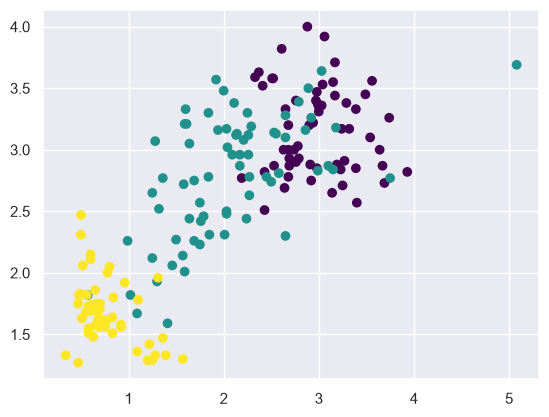

In [67]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(data.data[:, 6], data.data[:,  11], c=data.target)
plt.show()

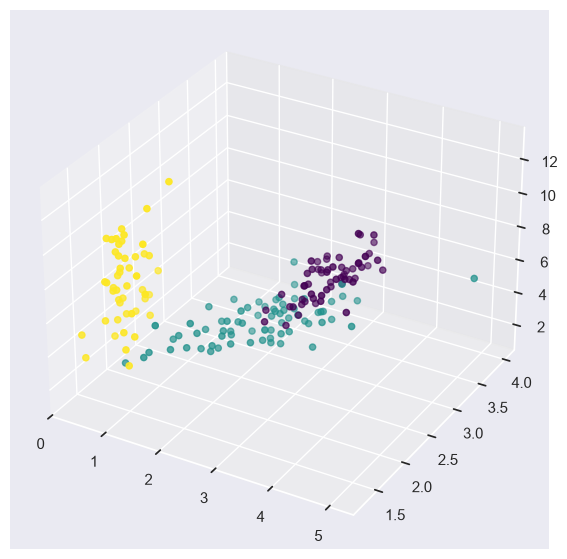

In [68]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(data.data[:, 6], data.data[:,  11], data.data[:,  9], c=data.target)

# show plot
plt.show()

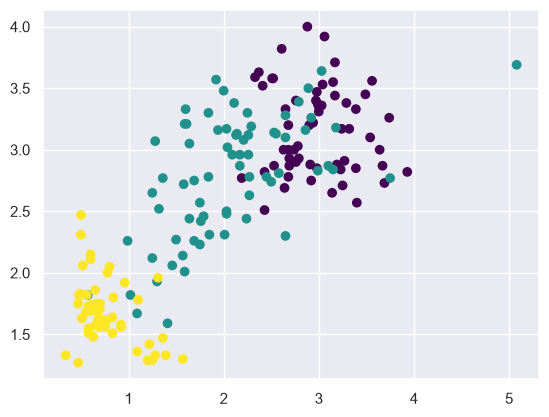

In [69]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(data.data[:, _cfs[0]], data.data[:,  _cfs[1]], c=data.target)
plt.show()

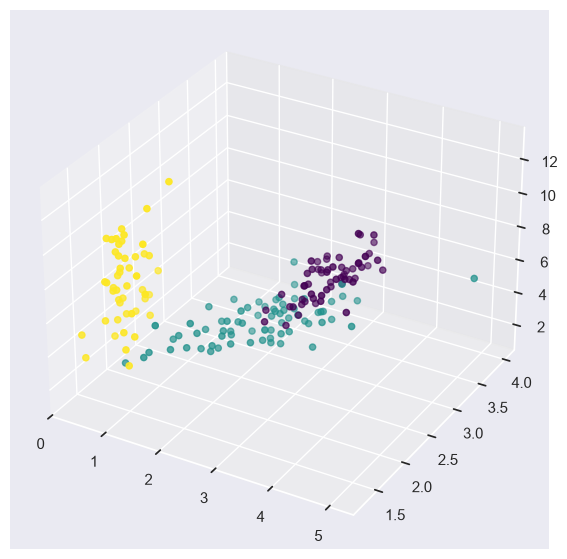

In [70]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(data.data[:, _cfs[0]], data.data[:,  _cfs[1]], data.data[:,  _cfs[2]], c=data.target)

# show plot
plt.show()

# Relief-F

In [49]:
#pip install sklearn_relief
import sklearn_relief as relief

#Relief, ReliefF, RReliefF
fs = relief.ReliefF(n_features=3)
X_relief = fs.fit_transform(data.data, data.target)

print("(No. of tuples, No. of Columns before ReliefF) : "+str(data.data.shape)+ "\n(No. of tuples, No. of Columns after ReliefF) : "+str(X_relief.shape))

(No. of tuples, No. of Columns before ReliefF) : (178, 13)
(No. of tuples, No. of Columns after ReliefF) : (178, 3)


In [73]:
#sel_X = X[:,feat_selector._support_mask]
sel_X = data.data[:,_cfs]

from sklearn.model_selection import train_test_split

#X_train, X_test, Y_train, Y_test = train_test_split(sel_X,y, test_size=0.25)
X_train, X_test, Y_train, Y_test = train_test_split(data.data,data.target, test_size=0.25)

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000)
lr.fit(X_train, Y_train)

print(lr.score(X_test, Y_test))

0.9777777777777777


In [52]:
lr = LogisticRegression(max_iter=10000)
#lr.fit(X_train, Y_train)
#print(lr.score(X_test, Y_test))

kfold = StratifiedKFold(10) #n_splits=10,  shuffle=False)

cv_results = cross_val_score(lr,X_relief,data.target, scoring='accuracy', cv=kfold)
#actual_classes, predicted_classes, _ = cross_val_predict(lr, kfold, data.data,data.target)
actual_classes, predicted_classes, _ = cross_val_predict(lr, kfold, X_relief,data.target)
print(cv_results.mean()) # 0.9666666666666666

0.9


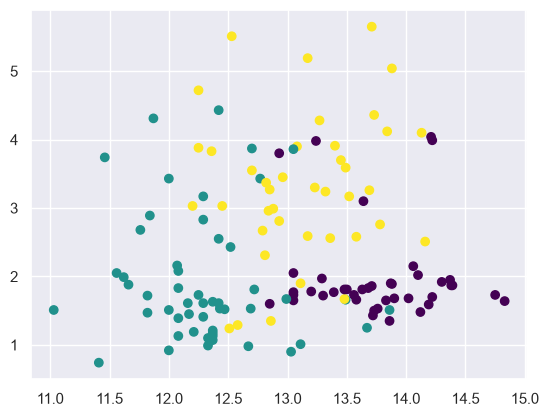

In [75]:
import matplotlib.pyplot as plt
plt.viridis()
#plt.scatter(X_train[:, 0], X_train[:,  1], c=data.target)
plt.scatter(X_train[:, 0], X_train[:,  1], c=Y_train)
plt.show()

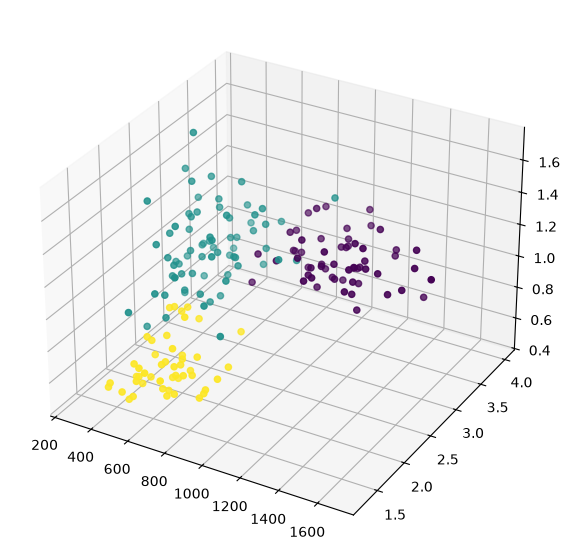

In [51]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
#ax.scatter3D(X_train[:, 0], X_train[:,  1], X_train[:,  2], c=data.target)

#ax.scatter3D(X_train[:, 0], X_train[:,  1], X_train[:,  2], c=Y_train)
ax.scatter3D(X_relief[:, 0], X_relief[:,  1], X_relief[:,  2], c=data.target)

# show plot
plt.show()

In [78]:
from scipy.stats import chi2_contingency
stat, p, dof, expected = chi2_contingency(data.data)

In [79]:
df = data.data

In [80]:
df

array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
        1.185e+03],
       ...,
       [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
        8.350e+02],
       [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
        8.400e+02],
       [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
        5.600e+02]], shape=(178, 13))

In [83]:
#----------step 1: Extract required columns, ideally it should be two columns at a time
data_interim=df[[0,5]]
#----------step 2: Create a cross tab which is a contigency table
#data_cont=pd.crosstab(data_interim[0], data_interim[5])
data_cont=pd.crosstab(data_interim[0], data_interim[1])
data_cont
from scipy.stats import chi2_contingency
stat, p, dof, expected = chi2_contingency(data_cont)
#-----------interpret p-value
alpha = 0.05
print("p value is " + str(p))
if p <= alpha:
    
    print('Dependent (reject H0)')
    
else:
    print('Independent (H0 holds true)')

p value is 0.23349082351103725
Independent (H0 holds true)


### Chi^2

In [53]:

from sklearn.feature_selection import chi2
from sklearn.feature_selection import SelectKBest

test = SelectKBest(score_func=chi2, k=3)
fit = test.fit(data.data,data.target)

X_new=test.fit_transform(data.data,data.target)

fit.scores_

array([5.44549882e+00, 2.80686046e+01, 7.43380598e-01, 2.93836955e+01,
       4.50263809e+01, 1.56230759e+01, 6.33343081e+01, 1.81548480e+00,
       9.36828307e+00, 1.09016647e+02, 5.18253981e+00, 2.33898834e+01,
       1.65400671e+04])

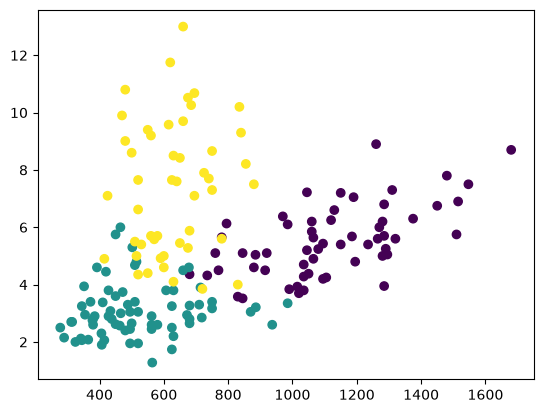

In [54]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(X_new[:, 2], X_new[:,  1], c=data.target)
plt.show()

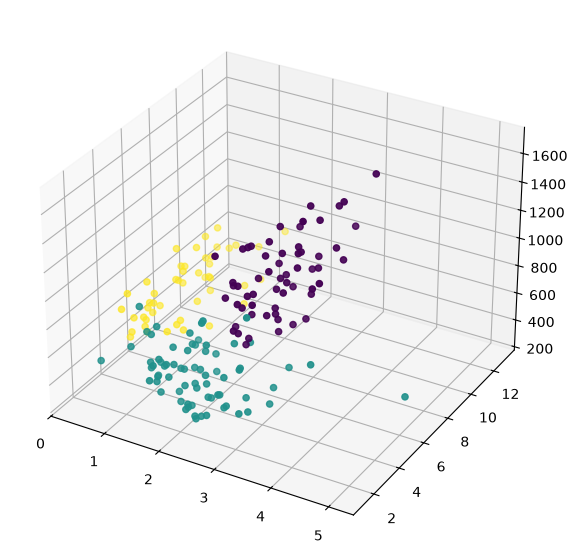

In [55]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(X_new[:, 0], X_new[:,  1], X_new[:,  2], c=data.target)

# show plot
plt.show()

# PCA - Principal Component Analysis

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

# Build a classification task using 3 informative features
X, y = make_classification(
    n_samples=1000,
    n_features=25,
    n_informative=3,
    n_redundant=12,
    n_repeated=0,
    n_classes=8,
    n_clusters_per_class=1,
    random_state=0,
)

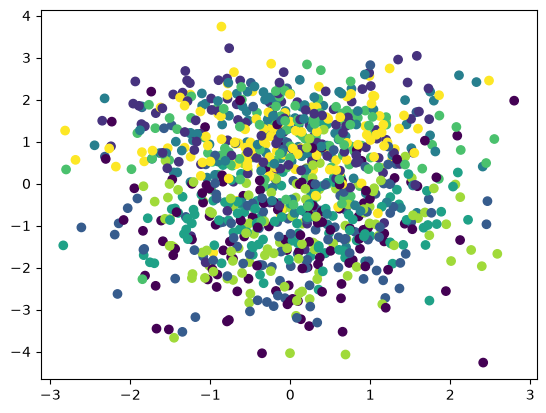

In [7]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.decomposition import SparsePCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

X_digits, y_digits = datasets.load_digits(return_X_y=True)
X = X_digits
y = y_digits
#X = data.data
#y = data.target

#pca = PCA()
sparse_pca = SparsePCA()

scaler = StandardScaler() # Define a Standard Scaler to normalize inputs

# set the tolerance to a large value to make the example faster
logistic = LogisticRegression(max_iter=10000, tol=0.1)

#spca = SparsePCA(n_components=36, alpha=0.1)

#pipe = Pipeline(steps=[("scaler", scaler), ("pca", pca), ("logistic", logistic)])
pipe = Pipeline(steps=[("scaler", scaler), ("sparse_pca", sparse_pca), ("logistic", logistic)])



In [24]:
# Parameters of pipelines can be set using '__' separated parameter names:
param_grid = {
#    "sparse_pca__n_components": [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 64],
   "sparse_pca__n_components": [5, 20,  30, 60],
#    "pca__n_components": [3,5,7,10,15,17,18,19,20,21,22,23,24,25],
#     "pca__n_components": [3,4,5,6,7,8,9,10,11,12,13],
    "logistic__C": np.logspace(-4, 4, 4),
}

search = GridSearchCV(pipe, param_grid, n_jobs=2)
search.fit(X, y)

print("Best parameter (CV score=%0.3f):" % search.best_score_)
print(search.best_params_)

#0.732

KeyboardInterrupt: 

In [ ]:
# Plot the PCA spectrum
#pca.fit(X)
sparse_pca.fit(X)

fig, (ax0, ax1) = plt.subplots(
    nrows=2,
    sharex=True,
    figsize=(6, 6)
)

# Variância explicada pelo PCA
ax0.plot(
    np.arange(1, pca.n_components_ + 1),
    pca.explained_variance_ratio_,
    "+",
    linewidth=2
)

ax0.set_ylabel("Razão da Variância Explicada do PCA")

# Número de componentes escolhido pelo GridSearch
best_n_components = (
    search.best_estimator_
    #.named_steps["pca"]
        .named_steps["sparse_pca"]
    .n_components
)

ax0.axvline(
    best_n_components,
    linestyle=":",
    label=f"Selecionado: {best_n_components}"
)

ax0.legend(prop=dict(size=12))


# Resultados do GridSearch
results = pd.DataFrame(search.cv_results_)

components_col = "param_sparse_pca__n_components"
#components_col = "param_pca__n_components"

# Melhor configuração para cada número de componentes
best_clfs = (
    results
    .sort_values("mean_test_score", ascending=False)
    .groupby(components_col, as_index=False)
    .first()
    .sort_values(components_col)
)

# Gráfico da acurácia
ax1.errorbar(
    best_clfs[components_col],
    best_clfs["mean_test_score"],
    yerr=best_clfs["std_test_score"],
    marker="o"
)

ax1.set_ylabel("Acurácia da Classificação")
ax1.set_xlabel("Número de componentes")

plt.xlim(0, sparse_pca.n_components_)
#plt.xlim(0, pca.n_components_)

plt.tight_layout()
plt.show()

In [18]:
#print(pca.explained_variance_)
#print(pca.components_[0])
for c in pca.components_:
    print(np.argmax(c))

34
44
29
61
42
52
27
13
45
36
12
51
35
58
4
60
43
51
12
26
52
17
36
38
37
4
62
11
13
21
38
25
10
60
25
59
61
59
3
49
59
49
46
14
2
63
2
7
57
55
15
1
47
23
48
40
8
16
31
24
56
39
0
32


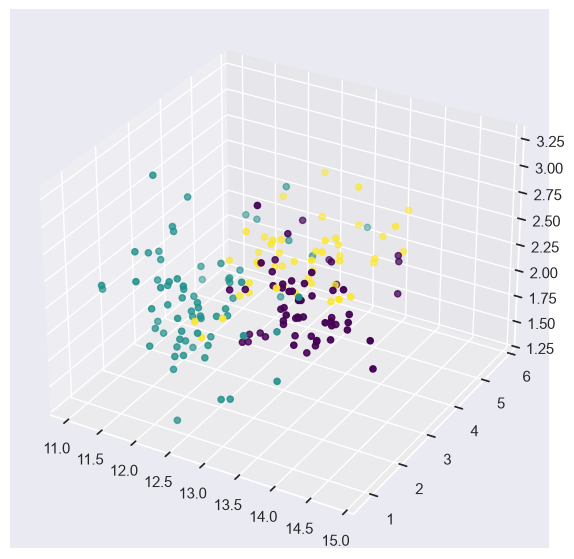

In [106]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(X[:, 0], X[:, 1], X[:, 2], c=y)
 
# show plot
plt.show()

In [108]:
sel_X = pca.transform(X)

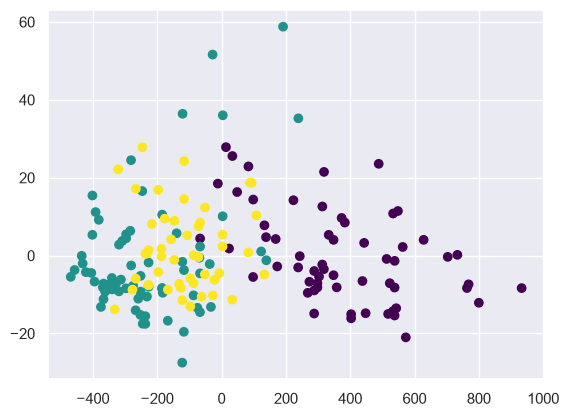

In [109]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(sel_X[:, 0], sel_X[:, 1], c=y)
plt.show()

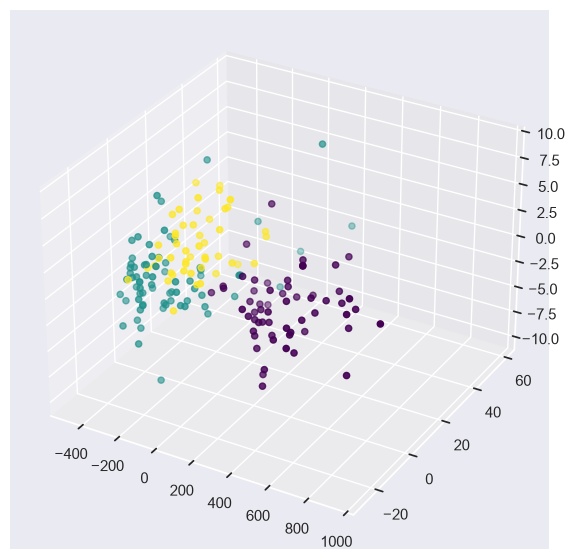

In [110]:
import matplotlib.pyplot as plt

# Creating figure
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
 
# Creating plot
ax.scatter3D(sel_X[:, 0], sel_X[:, 1], sel_X[:, 2], c=y)
 
# show plot
plt.show()

### Exemplo 2 PCA:

In [111]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_wine
from sklearn.pipeline import make_pipeline

# Code source: Tyler Lanigan <tylerlanigan@gmail.com>
#              Sebastian Raschka <mail@sebastianraschka.com>

# License: BSD 3 clause

RANDOM_STATE = 42
FIG_SIZE = (10, 7)

features, target = load_wine(return_X_y=True)

# Make a train/test split using 30% test size
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.30, random_state=RANDOM_STATE
)

# Fit to data and predict using pipelined GNB and PCA
#unscaled_clf = make_pipeline(PCA(n_components=2), GaussianNB())
unscaled_clf = make_pipeline(PCA(n_components=2), LogisticRegression(max_iter=10000, tol=0.1))
unscaled_clf.fit(X_train, y_train)
pred_test = unscaled_clf.predict(X_test)

# Fit to data and predict using pipelined scaling, GNB and PCA
#std_clf = make_pipeline(StandardScaler(), PCA(n_components=2), GaussianNB())
std_clf = make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=10000, tol=0.1))
std_clf.fit(X_train, y_train)
pred_test_std = std_clf.predict(X_test)

# Show prediction accuracies in scaled and unscaled data.
print("\nPrediction accuracy for the normal test dataset with PCA")
print(f"{accuracy_score(y_test, pred_test):.2%}\n")

print("\nPrediction accuracy for the standardized test dataset with PCA")
print(f"{accuracy_score(y_test, pred_test_std):.2%}\n")

# Extract PCA from pipeline
pca = unscaled_clf.named_steps["pca"]
pca_std = std_clf.named_steps["pca"]

# Show first principal components
print(f"\nPC 1 without scaling:\n{pca.components_[0]}")
print(f"\nPC 1 with scaling:\n{pca_std.components_[0]}")

# Use PCA without and with scale on X_train data for visualization.
X_train_transformed = pca.transform(X_train)

scaler = std_clf.named_steps["standardscaler"]
scaled_X_train = scaler.transform(X_train)
X_train_std_transformed = pca_std.transform(scaled_X_train)




Prediction accuracy for the normal test dataset with PCA
72.22%


Prediction accuracy for the standardized test dataset with PCA
98.15%


PC 1 without scaling:
[ 1.76342917e-03 -8.35544737e-04  1.54623496e-04 -5.31136096e-03
  2.01663336e-02  1.02440667e-03  1.53155502e-03 -1.11663562e-04
  6.31071580e-04  2.32645551e-03  1.53606718e-04  7.43176482e-04
  9.99775716e-01]

PC 1 with scaling:
[ 0.13443023 -0.25680248 -0.0113463  -0.23405337  0.15840049  0.39194918
  0.41607649 -0.27871336  0.33129255 -0.11383282  0.29726413  0.38054255
  0.27507157]


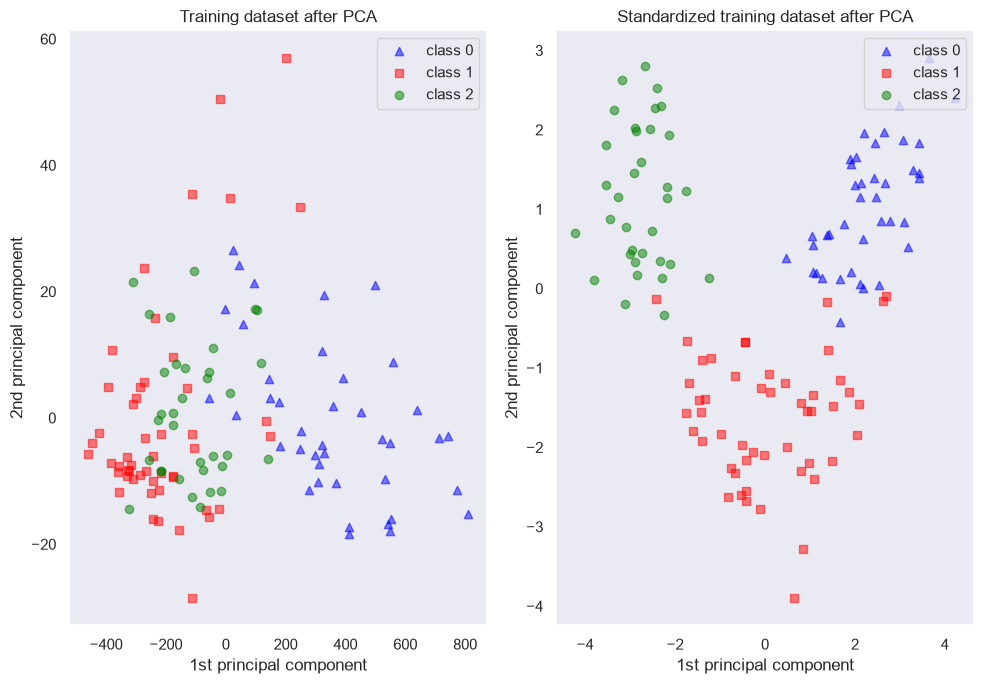

In [112]:
# visualize standardized vs. untouched dataset with PCA performed
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=FIG_SIZE)

target_classes = range(0, 3)
colors = ("blue", "red", "green")
markers = ("^", "s", "o")

for target_class, color, marker in zip(target_classes, colors, markers):
    ax1.scatter(
        x=X_train_transformed[y_train == target_class, 0],
        y=X_train_transformed[y_train == target_class, 1],
        color=color,
        label=f"class {target_class}",
        alpha=0.5,
        marker=marker,
    )

    ax2.scatter(
        x=X_train_std_transformed[y_train == target_class, 0],
        y=X_train_std_transformed[y_train == target_class, 1],
        color=color,
        label=f"class {target_class}",
        alpha=0.5,
        marker=marker,
    )

ax1.set_title("Training dataset after PCA")
ax2.set_title("Standardized training dataset after PCA")

for ax in (ax1, ax2):
    ax.set_xlabel("1st principal component")
    ax.set_ylabel("2nd principal component")
    ax.legend(loc="upper right")
    ax.grid()

plt.tight_layout()

plt.show()

### Exemplo 3 PCA MNIST:

In [113]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

digits = load_digits()

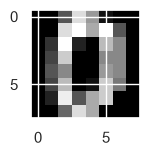

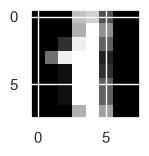

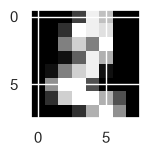

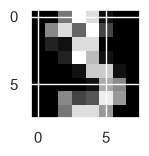

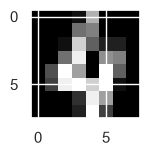

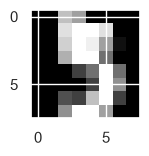

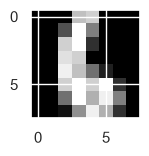

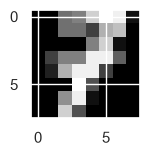

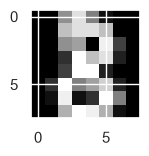

In [114]:
from matplotlib import pyplot

X_train = digits.data

for i in range(9):  
    pyplot.subplot(330 + 1 + i)
    shape = (8,8)
    im = X_train[i].reshape(shape)
    pyplot.imshow(im, cmap=pyplot.get_cmap('gray'))
    pyplot.show()    

In [115]:
pca = PCA(n_components=36, whiten=True)
X_pca = pca.fit_transform(digits.data / 255)

In [116]:
print(pca.explained_variance_ratio_)

[0.14890594 0.13618771 0.11794594 0.08409979 0.05782415 0.0491691
 0.04315987 0.03661373 0.03353248 0.03078806 0.02372341 0.02272697
 0.01821863 0.01773855 0.01467101 0.01409716 0.01318589 0.01248138
 0.01017718 0.00905617 0.00889538 0.00797123 0.00767493 0.00722904
 0.00695889 0.00596081 0.00575615 0.00515158 0.0048954  0.00428888
 0.00373606 0.00353274 0.00336684 0.0032803  0.00308321 0.00293779]


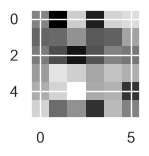

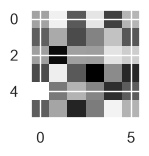

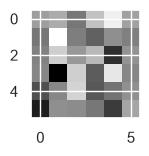

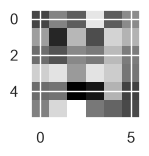

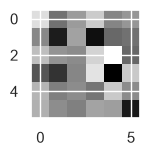

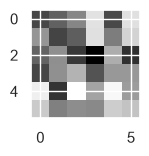

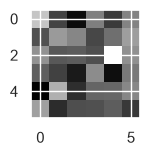

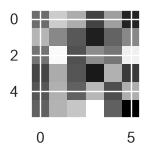

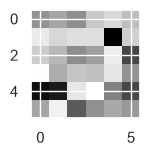

In [117]:
from matplotlib import pyplot

X_train = X_pca

for i in range(9):  
    pyplot.subplot(330 + 1 + i)
    shape = (6,6)
    im = X_train[i].reshape(shape)
    pyplot.imshow(im, cmap=pyplot.get_cmap('gray'))
    pyplot.show()    

In [118]:
X_rebuilt = pca.inverse_transform(X_pca)

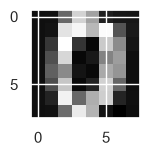

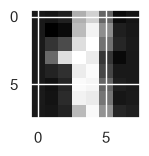

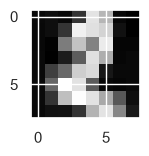

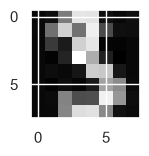

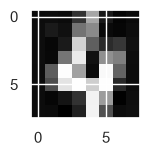

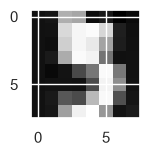

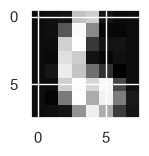

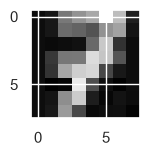

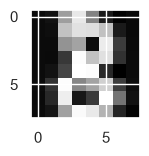

In [119]:
from matplotlib import pyplot

X_train = X_rebuilt

for i in range(9):  
    pyplot.subplot(330 + 1 + i)
    shape = (8,8)
    im = X_train[i].reshape(shape)
    pyplot.imshow(im, cmap=pyplot.get_cmap('gray'))
    pyplot.show()    

# Sparse PCA

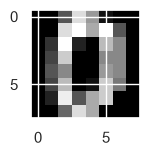

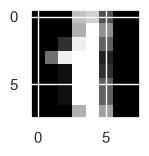

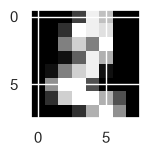

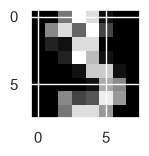

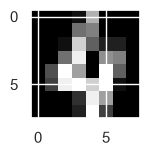

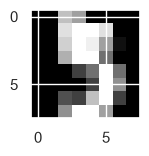

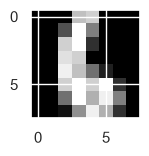

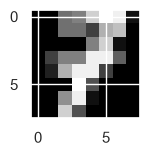

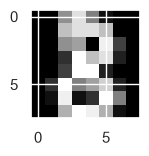

In [120]:
from matplotlib import pyplot

X_train = digits.data

for i in range(9):  
    pyplot.subplot(330 + 1 + i)
    shape = (8,8)
    im = X_train[i].reshape(shape)
    pyplot.imshow(im, cmap=pyplot.get_cmap('gray'))
    pyplot.show()    

In [26]:
from sklearn.decomposition import SparsePCA

spca = SparsePCA(n_components=36, alpha=0.1)
X_spca = spca.fit_transform(X_digits / 255)

print(spca.components_.shape)

(36, 64)


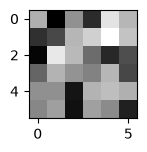

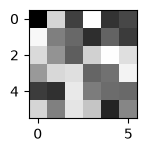

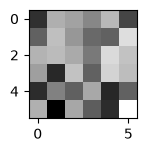

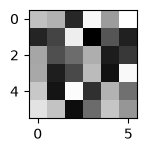

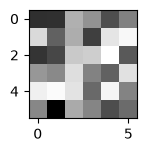

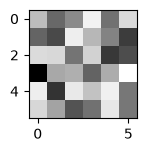

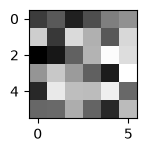

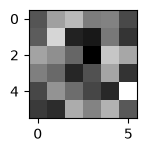

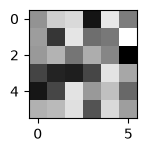

In [27]:
from matplotlib import pyplot

X_train = X_spca

for i in range(9):  
    pyplot.subplot(330 + 1 + i)
    shape = (6,6)
    im = X_train[i].reshape(shape)
    pyplot.imshow(im, cmap=pyplot.get_cmap('gray'))
    pyplot.show()    

In [123]:
Xs_rebuilt = (X_spca @ spca.components_) + spca.mean_

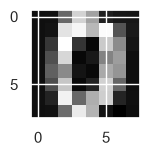

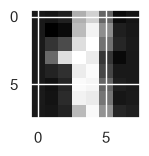

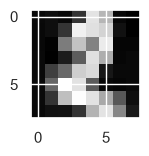

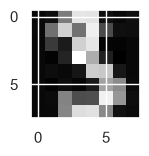

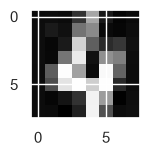

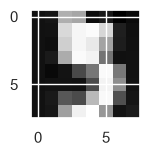

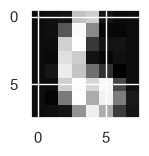

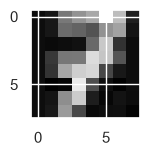

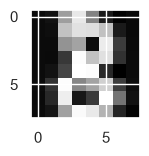

In [124]:
from matplotlib import pyplot

X_train = X_rebuilt

for i in range(9):  
    pyplot.subplot(330 + 1 + i)
    shape = (8,8)
    im = X_train[i].reshape(shape)
    pyplot.imshow(im, cmap=pyplot.get_cmap('gray'))
    pyplot.show()    

# Kernel PCA

In [28]:
from sklearn.datasets import make_circles

Xb, Yb = make_circles(n_samples=500, factor=0.1, noise=0.05)

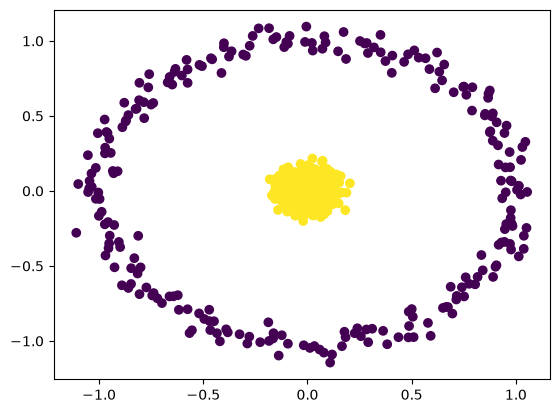

In [30]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(Xb[:, 0], Xb[:, 1], c=Yb)
plt.show()

In [31]:
from sklearn.decomposition import KernelPCA

kpca = KernelPCA(n_components=2, kernel='rbf', fit_inverse_transform=True, gamma=1.0)
X_kpca = kpca.fit_transform(Xb)

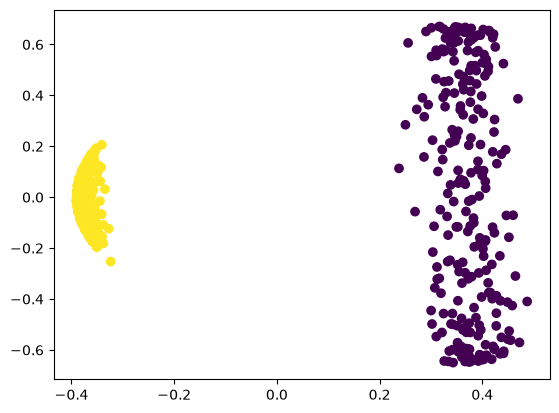

In [32]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(X_kpca[:, 0], X_kpca[:, 1], c=Yb)
plt.show()

# ICA - Independent Component Analysis

In [129]:
import numpy as np

from sklearn.datasets import fetch_openml


def zero_center(Xd):
    return Xd - np.mean(Xd, axis=0)

digits = fetch_openml("mnist_784")

X = zero_center(digits['data'].astype(np.float64))
#np.random.shuffle(X)

In [130]:
shuffled_df = X.sample(n=len(X))
# Reset the index of the shuffled DataFrame
shuffled_df = shuffled_df.reset_index(drop=True)
X = shuffled_df

In [131]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
Y = le.fit_transform(digits.target).ravel()

In [132]:
from sklearn.decomposition import FastICA

fastica = FastICA(n_components=256, max_iter=5000, random_state=1000)
fastica.fit(X)

,"n_components n_components: int, default=NoneNumber of components to use. If None is passed, all are used.",256
,"max_iter max_iter: int, default=200Maximum number of iterations during fit.",5000
,"random_state random_state: int, RandomState instance or None, default=NoneUsed to initialize ``w_init`` when not specified, with anormal distribution. Pass an int, for reproducible resultsacross multiple function calls.See :term:`Glossary <random_state>`.",1000
,"algorithm algorithm: {'parallel', 'deflation'}, default='parallel'Specify which algorithm to use for FastICA.",'parallel'
,"whiten whiten: str or bool, default='unit-variance'Specify the whitening strategy to use.- If 'arbitrary-variance', a whitening with variance arbitrary is used.- If 'unit-variance', the whitening matrix is rescaled to ensure that each recovered source has unit variance.- If False, the data is already considered to be whitened, and no whitening is performed... versionchanged:: 1.3 The default value of `whiten` changed to 'unit-variance' in 1.3.",'unit-variance'
,"fun fun: {'logcosh', 'exp', 'cube'} or callable, default='logcosh'The functional form of the G function used in theapproximation to neg-entropy. Could be either 'logcosh', 'exp',or 'cube'.You can also provide your own function. It should return a tuplecontaining the value of the function, and of its derivative, in thepoint. The derivative should be averaged along its last dimension.Example:: def my_g(x): return x ** 3, (3 * x ** 2).mean(axis=-1)",'logcosh'
,"fun_args fun_args: dict, default=NoneArguments to send to the functional form.If empty or None and if fun='logcosh', fun_args will take value{'alpha' : 1.0}.",None
,"tol tol: float, default=1e-4A positive scalar giving the tolerance at which theun-mixing matrix is considered to have converged.",0.0001
,"w_init w_init: array-like of shape (n_components, n_components), default=NoneInitial un-mixing array. If `w_init=None`, then an array of valuesdrawn from a normal distribution is used.",None
,"whiten_solver whiten_solver: {""eigh"", ""svd""}, default=""svd""The solver to use for whitening.- ""svd"" is more stable numerically if the problem is degenerate, and often faster when `n_samples <= n_features`.- ""eigh"" is generally more memory efficient when `n_samples >= n_features`, and can be faster when `n_samples >= 50 * n_features`... versionadded:: 1.2",'svd'
Name,Type,Value


In [133]:
X_fastica = fastica.transform(X)

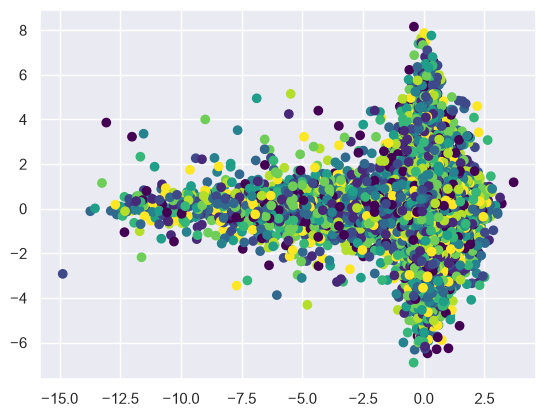

In [134]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(X_fastica[:, 0], X_fastica[:, 1], c=Y)
plt.show()

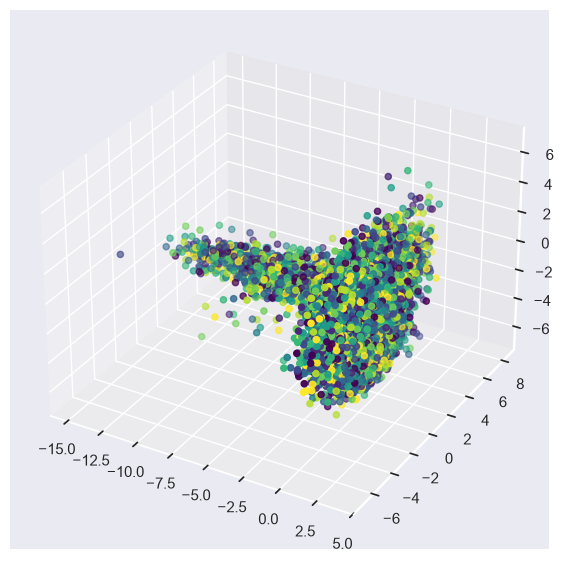

In [135]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
ax.scatter3D(X_fastica[:, 0], X_fastica[:,  1], X_fastica[:,  2], c=Y)
plt.show()

# t-SNE - t-Distributed Stochastic Neighbor Embedding 

In [33]:
import numpy as np

from sklearn.datasets import load_digits

digits = load_digits()
X = digits['data'] / np.max(digits['data'])

In [34]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=20, random_state=1000, learning_rate=200, init='pca')
X_tsne = tsne.fit_transform(X)

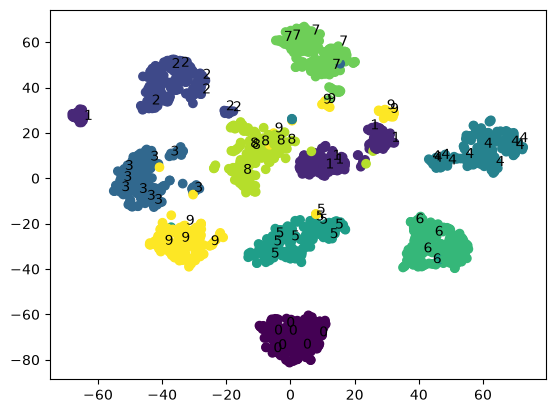

In [35]:
import matplotlib.pyplot as plt
plt.viridis()
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target)

for i in range(len(X_tsne)):
    if i % 25 == 0:
        plt.text(x=X_tsne[i][0]+0.3,y=X_tsne[i][1]+0.3,s=digits.target[i])

    
plt.show()